In [1]:
%pip install -q tensorflow tensorflow-datasets matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install importlib-resources

Note: you may need to restart the kernel to use updated packages.


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10
GPU devices: []


In [15]:
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

class_names = ds_info.features["label"].names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Training examples:", ds_info.splits["train"].num_examples * 0.70)
print("Dataset loaded.")

Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5
Training examples: 2569.0
Dataset loaded.


In [16]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.one_hot(label, depth=num_classes)
    return image, label

train_ds = (
    ds_train
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = (
    ds_val
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    ds_test
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Image preprocessing completed.")

Image preprocessing completed.


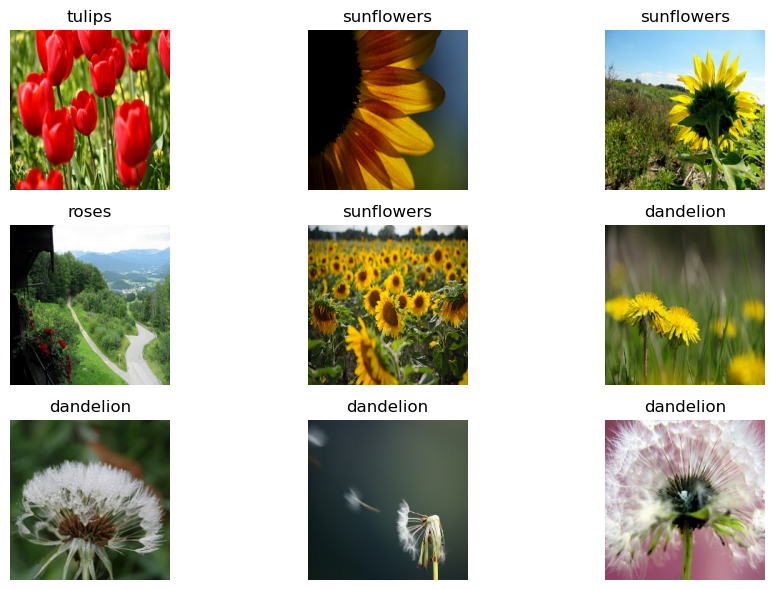

In [17]:
# Display 9 images from the raw dataset
import tensorflow as tf
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for images, labels in ds_train.map(
    lambda image, label: (
        tf.image.resize(image, (224, 224)),
        label
    )
).batch(9).take(1):

    for i in range(len(images)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

print("VGG16 loaded.")
print("Base model output shape:", base_model.output_shape)

VGG16 loaded.
Base model output shape: (None, 4, 4, 512)


In [19]:
base_model.trainable = False
print("Base model trainable:", base_model.trainable)

Base model trainable: False


In [20]:
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,862,789 (56.70 MB)

 Trainable params: 148,101 (578.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [21]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.6080 - loss: 1.6613 - val_accuracy: 0.7187 - val_loss: 0.7896 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.7626 - loss: 0.7290 - val_accuracy: 0.8076 - val_loss: 0.5502 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 265s 3s/step - accuracy: 0.8248 - loss: 0.5233 - val_accuracy: 0.7840 - val_loss: 0.5750 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 265s 3s/step - accuracy: 0.8462 - loss: 0.4256 - val_accuracy: 0.7822 - val_loss: 0.5806 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 272s 3s/step - accuracy: 0.8863 - loss: 0.3256 - val_accuracy: 0.8094 - val_loss: 0.5146 - learning_rate: 2.0000e-04


In [22]:
print("Training epochs completed:", len(history.history["loss"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))
print("Final training accuracy:", history.history["accuracy"][-1])

Training epochs completed: 5
Best validation accuracy: 0.8094373941421509
Best validation loss: 0.5146311521530151
Final training accuracy: 0.8863371014595032


In [23]:
print("Epochs recorded:", len(history.history["loss"]))

print("Best epoch:",
      history.history["val_loss"].index(
          min(history.history["val_loss"])
      ) + 1)

print("Early stopping patience:",
      callbacks[0].patience)

print("Restore best weights:",
      callbacks[0].restore_best_weights)

Epochs recorded: 5
Best epoch: 5
Early stopping patience: 4
Restore best weights: True


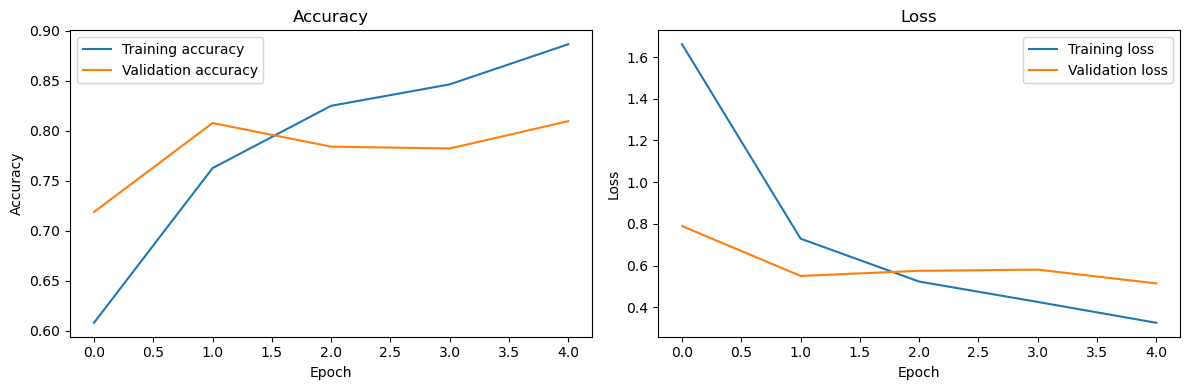

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [25]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 49s 3s/step - accuracy: 0.8291 - loss: 0.4942
Test loss: 0.4942
Test accuracy: 0.8291
Test accuracy (%): 82.91%


In [26]:
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

   dandelion       0.87      0.90      0.89       112
       daisy       0.88      0.77      0.82        95
      tulips       0.83      0.78      0.80       134
  sunflowers       0.85      0.84      0.85       102
       roses       0.74      0.86      0.80       107

    accuracy                           0.83       550
   macro avg       0.83      0.83      0.83       550
weighted avg       0.83      0.83      0.83       550



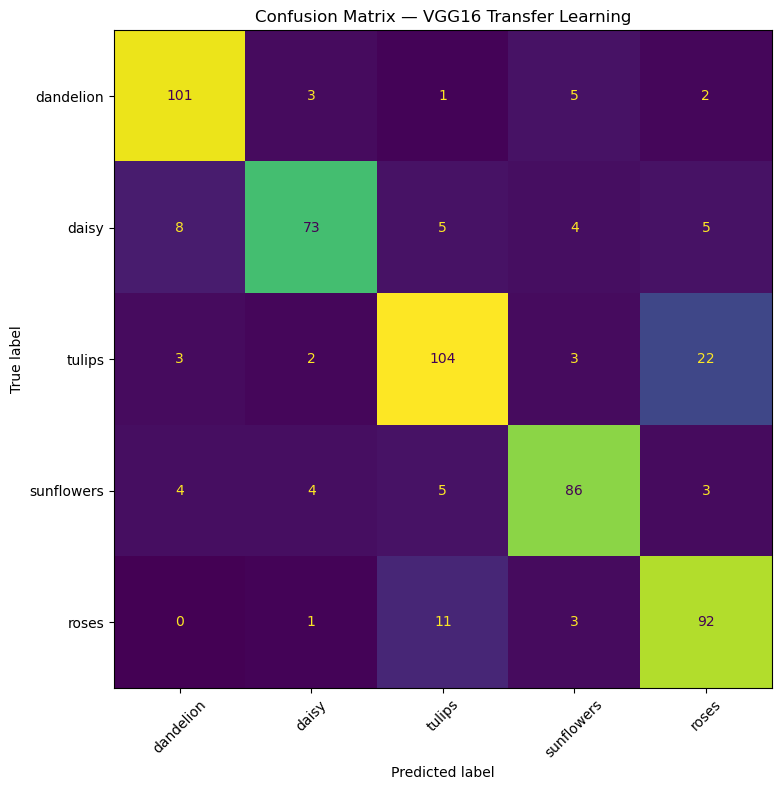

In [27]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
display.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — VGG16 Transfer Learning")
plt.tight_layout()
plt.show()

In [28]:
# Unfreeze the base model, then freeze all layers except the final convolutional block.
base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

# Recompile after changing trainable layers.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable base-model layers:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable base-model layers:
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [29]:
fine_tune_callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7)
]

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks
)

fine_test_loss, fine_test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Fine-tuned test loss: {fine_test_loss:.4f}")
print(f"Fine-tuned test accuracy: {fine_test_accuracy:.4f}")
print(f"Fine-tuned test accuracy (%): {fine_test_accuracy * 100:.2f}%")

Epoch 1/5


C:\Users\DELL\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 325s 4s/step - accuracy: 0.9046 - loss: 0.2637 - val_accuracy: 0.8185 - val_loss: 0.4912 - learning_rate: 1.0000e-05
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 316s 4s/step - accuracy: 0.9315 - loss: 0.1993 - val_accuracy: 0.8421 - val_loss: 0.4694 - learning_rate: 1.0000e-05
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 317s 4s/step - accuracy: 0.9404 - loss: 0.1705 - val_accuracy: 0.8512 - val_loss: 0.4729 - learning_rate: 1.0000e-05
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 318s 4s/step - accuracy: 0.9564 - loss: 0.1310 - val_accuracy: 0.8675 - val_loss: 0.4389 - learning_rate: 1.0000e-05
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 320s 4s/step - accuracy: 0.9638 - loss: 0.1137 - val_accuracy: 0.8603 - val_loss: 0.4457 - learning_rate: 1.0000e-05
18/18 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.8891 - loss: 0.3885
Fine-tuned test loss: 0.3885
Fine-tuned test accuracy: 0.8891
Fine-tuned test accuracy (%): 88.91%


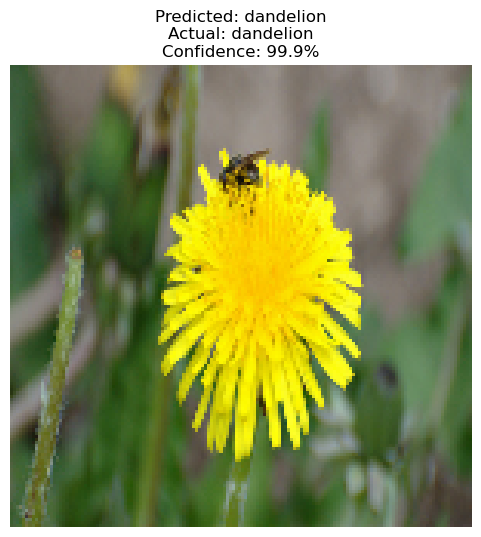

In [30]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

correct_image = None
correct_label = None
correct_prediction = None
correct_confidence = None

# Resize images before batching so all shapes match
resized_test_ds = ds_test.map(
    lambda image, label: (
        tf.image.resize(image, IMG_SIZE),
        label
    )
).batch(16)

for raw_images, raw_labels in resized_test_ds:

    # VGG16 preprocessing
    processed_images = preprocess_input(
        tf.cast(raw_images, tf.float32)
    )

    probabilities = model.predict(
        processed_images, verbose=0
    )

    predicted_indices = np.argmax(probabilities, axis=1)
    actual_indices = raw_labels.numpy().astype(int)

    # Find correctly classified images
    matches = np.where(
        predicted_indices == actual_indices
    )[0]

    if len(matches) > 0:
        i = matches[0]

        correct_image = raw_images[i].numpy().astype("uint8")
        correct_label = actual_indices[i]
        correct_prediction = predicted_indices[i]
        correct_confidence = (
            probabilities[i][correct_prediction] * 100
        )
        break

if correct_image is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(correct_image)
    plt.title(
        f"Predicted: {class_names[correct_prediction]}\n"
        f"Actual: {class_names[correct_label]}\n"
        f"Confidence: {correct_confidence:.1f}%"
    )
    plt.axis("off")
    plt.show()
else:
    print("No correctly classified image was found.")

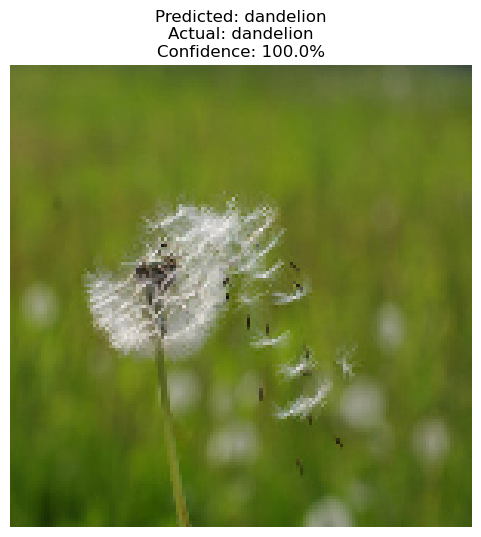

In [31]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

# Resize images before batching
resized_test_ds = ds_test.map(
    lambda image, label: (
        tf.image.resize(image, IMG_SIZE),
        label
    )
).batch(16)

# Collect one batch and choose a random image
images, labels = next(iter(resized_test_ds))
i = random.randrange(len(images))

# Preprocess the selected image
selected_image = images[i:i+1]
processed_image = preprocess_input(
    tf.cast(selected_image, tf.float32)
)

# Predict flower class
probabilities = model.predict(processed_image, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
actual_index = int(labels[i].numpy())

# Display prediction
plt.figure(figsize=(6, 6))
plt.imshow(images[i].numpy().astype("uint8"))
plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_index]}\n"
    f"Confidence: {probabilities[predicted_index] * 100:.1f}%"
)
plt.axis("off")
plt.show()